#Задача
Виконати донавчання мовної моделі, щоб покращити її здатність відповідати на запитання про гру Baldur’s Gate 3 (BG3).

Очікується, що після донавчання модель краще знатиме особливості гри, не плутатиме її механіки з правилами настільної Dungeons & Dragons, не вигадуватиме відповіді за відсутності достатньої інформації та відмовлятиметься відповідати на запитання, які не стосуються BG3.

#Модель і дані
##Модель
У попередній роботі було використано модель Gemma 3 4B IT. Вона стабільно генерує відповіді, хоча не завжди правильні саме стосовно гри BG3. Водночас модель уже має певні знання про Dungeons & Dragons, на основі якої створена гра, тому вона є непоганою основою для подальшого донавчання.

Модель відносно невелика за розміром, тому її можна використовувати в середовищі Google Colab. Для донавчання планується застосувати метод QLoRA.

##Дані
Для донавчання планується підготувати власний набір даних на основі інформації з BG3 Wiki. Дані будуть представлені у структурованому форматі JSON із зазначенням категорії, назви, опису, ключових слів і джерела інформації.

Основна увага приділятиметься базовим ігровим знанням, які допомагають гравцеві створювати персонажа та приймати рішення під час гри.

До набору даних планується включити:
- Характеристики персонажів: шість основних характеристик, їхнє призначення та вплив на ігрові механіки.
- Класи та підкласи: усі 12 класів, їхні особливості, доступні підкласи та рівні їх отримання.
- Раси та підраси: доступні раси, їхні особливості, расові здібності та бонуси.
- Загальні рекомендації щодо спорядження: які типи зброї та спорядження підходять певним класам і стилям гри, без необхідності вивчати конкретні предмети.
Інформацію про конкретні предмети, їхні характеристики, квести та сюжетні події на цьому етапі включати не планується.

#Модель до донавчання

In [1]:
!pip install -q transformers accelerate bitsandbytes "huggingface_hub>=0.25,<2.0" "pandas==2.2.3"

In [2]:
import torch
from huggingface_hub import notebook_login

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Не знайдено")

notebook_login()

GPU: Tesla T4


In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "google/gemma-3-4b-it"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float32,
    attn_implementation="eager"
)

model.eval()

print("Модель завантажена")
print("Тип моделі:", model.dtype)
print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Модель завантажена
Тип моделі: torch.float32
GPU: Tesla T4


In [4]:
import time
import torch

SYSTEM_PROMPT = """
Ти — ігровий помічник, який спеціалізується виключно на Baldur's Gate 3 (BG3).

Основні правила:

1. Тематика відповідей:
- Відповідай лише на запитання, що стосуються Baldur's Gate 3.
- На запитання з інших тем ввічливо відмовляйся відповідати.
- Якщо запитання лише частково стосується BG3, відповідай тільки на ту його частину, яка пов'язана з грою.

2. Точність інформації:
- Надавай достовірну інформацію про ігрові механіки, класи, підкласи, раси, характеристики та спорядження.
- Не плутай механіки Baldur's Gate 3 з правилами настільної Dungeons & Dragons.
- Не вигадуй характеристики предметів, здібності, правила або інші ігрові факти.
- Якщо не знаєш відповіді або не впевнений у її правильності, чесно повідом про це.

3. Рекомендації:
- Надавай практичні рекомендації щодо створення персонажів, вибору класів, рас, характеристик, зброї та стилю гри.
- Враховуй особливості класу, раси, характеристик і доступних володінь персонажа.
- Якщо запитують про конкретний предмет, але його характеристики невідомі, не вигадуй їх.

4. Захист від спойлерів:
- Не розкривай сюжетні повороти, завершення квестів, долі персонажів та інші важливі сюжетні подробиці.
- Не повідомляй, де знаходяться унікальні сюжетні предмети та як їх отримати, якщо це може розкрити сюжет.
- Якщо користувач просить розповісти спойлери, ввічливо попередь, що не надаєш такої інформації.

5. Формат відповідей:
- Відповідай українською мовою.
- Пиши зрозуміло, структуровано та по суті.
- Не додавай зайвої інформації, яка не стосується запитання.
"""

def ask_model(question):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    torch.cuda.synchronize()
    start_time = time.time()

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False
        )

    torch.cuda.synchronize()
    elapsed = time.time() - start_time

    input_length = inputs["input_ids"].shape[-1]
    generated_tokens = outputs[0][input_length:]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    token_count = len(generated_tokens)

    return {
        "answer": answer,
        "time": round(elapsed, 2),
        "tokens": token_count,
        "tokens_per_second": round(token_count / elapsed, 2) if elapsed > 0 else 0
    }

#Початкове тестування

In [5]:
questions = [
    # Знання про BG3
    "Які шість основних характеристик існують у Baldur's Gate 3?",
    "Назви всі доступні класи в Baldur's Gate 3.",
    "На якому рівні Плут обирає підклас?",
    "Які расові особливості має напіворк у Baldur's Gate 3?",

    # Практичні рекомендації
    "Яку зброю порадиш для Плута, який спеціалізується на прихованих атаках?",
    "Які характеристики найважливіші для персонажа класу Чарівник і чому?",

    # Перевірка відмови від сторонніх тем
    "Який найкращий спосіб вивчити Python?",
    "Поясни, як працює фотосинтез.",

    # Перевірка захисту від спойлерів
    "Розкажи, чим закінчується сюжет Baldur's Gate 3.",
    "Розкажи про важливі сюжетні повороти, пов'язані з компаньйонами."
]

In [6]:
import pandas as pd
results = []

for i, question in enumerate(questions):
    result = ask_model(question)

    results.append({
        "№": i + 1,
        "Питання": question,
        "Відповідь": result["answer"],
        "Час (с)": result["time"],
        "Токени": result["tokens"],
        "Токенів/с": result["tokens_per_second"]
    })

    print(f"Питання {i + 1}: {question}")
    print("Відповідь:", result["answer"])
    print("-" * 80)

df = pd.DataFrame(results)
display(df)

Питання 1: Які шість основних характеристик існують у Baldur's Gate 3?
Відповідь: У Baldur's Gate 3 існують шість основних характеристик, які впливають на успіх ваших дій у грі:

1.  **Сила (Strength):** Впливає на фізичну силу, здатність нести вантажі, наносити більший урон зброєю та піднімати важкі предмети.
2.  **Спритність (Dexterity):** Впливає на спритність, точність кидків, швидкість пересування, успіх у вкраденні та використання деяких типів зброї.
3.  **Інтелект (Intelligence):** Впливає на знання, здатність розгадувати головоломки, використовувати магію та успіх у дослідженнях.
4.  **Мудрість (Wisdom):** Впливає на інтуїцію, здатність відчувати небезпеку, успіх у магії та взаємодії з персонажами.
5.  **Харизма (Charisma):** Впливає на переконання, дипломатію, продаж товарів та успіх у взаємодії з іншими персонажами.
6.  **Конституція (Constitution):** Впливає на здоров'я, стійкість до хвороб та отрут, а також максимальне здоров'я персонажа
------------------------------------

,№,Питання,Відповідь,Час (с),Токени,Токенів/с
0,1,Які шість основних характеристик існують у Bal...,У Baldur's Gate 3 існують шість основних харак...,33.40,300,8.98
1,2,Назви всі доступні класи в Baldur's Gate 3.,У Baldur's Gate 3 доступні наступні класи:\n\n...,31.46,285,9.06
2,3,На якому рівні Плут обирає підклас?,Плут у Baldur's Gate 3 може обирати з кількох ...,32.23,300,9.31
3,4,Які расові особливості має напіворк у Baldur's...,Напіворки в Baldur's Gate 3 мають унікальні ра...,33.14,300,9.05
4,5,"Яку зброю порадиш для Плута, який спеціалізуєт...","Привіт! Чудове питання! Для Плута, який спеціа...",33.06,300,9.07
5,6,Які характеристики найважливіші для персонажа ...,Для класу Чарівника в Baldur's Gate 3 найважли...,32.13,300,9.34
6,7,Який найкращий спосіб вивчити Python?,"Вибачте, але я спеціалізуюся виключно на Baldu...",9.24,82,8.88
7,8,"Поясни, як працює фотосинтез.","Вибачте, але я спеціалізуюся виключно на Baldu...",8.86,82,9.25
8,9,"Розкажи, чим закінчується сюжет Baldur's Gate 3.","Я не можу розповісти тобі, чим закінчується сю...",32.53,300,9.22
9,10,"Розкажи про важливі сюжетні повороти, пов'язан...",Я не можу розповісти про важливі сюжетні повор...,32.65,300,9.19


#Метрики
Середня оцінка правильності відповідей (Mean Accuracy за заданою шкалою оцінювання).

In [7]:
scores = [0.8, 0.3, 0.0, 0.0, 0.5, 0.5, 1.0, 1.0, 1.0, 1.0]

# Загальна оцінка
overall_accuracy = sum(scores) / len(scores) * 100

# Оцінки за категоріями
bg3_accuracy = sum(scores[:6]) / 6 * 100
refusal_rate = sum(scores[6:8]) / 2 * 100
spoiler_protection = sum(scores[8:10]) / 2 * 100

print(f"Загальна оцінка якості: {overall_accuracy:.1f}%")
print(f"Знання BG3: {bg3_accuracy:.1f}%")
print(f"Відмова від сторонніх тем: {refusal_rate:.1f}%")
print(f"Захист від спойлерів: {spoiler_protection:.1f}%")

Загальна оцінка якості: 61.0%
Знання BG3: 35.0%
Відмова від сторонніх тем: 100.0%
Захист від спойлерів: 100.0%


#Висновок до початкового тестування:

За результатами початкового тестування загальна оцінка моделі становить 61%. На перший погляд, це непоганий результат, проте він не відображає реального рівня знань моделі про Baldur's Gate 3. Високий загальний показник забезпечений насамперед правильними відмовами від сторонніх тем і захистом від спойлерів.

Якщо розглядати саме знання ігрових механік, класів, рас та характеристик, результат становить лише 35%.

#Донавчання

In [10]:
import os
import json

FILE_PATH = "/content/data.json"

if os.path.exists(FILE_PATH):
    print("Файл знайдено!")

    with open(FILE_PATH, "r", encoding="utf-8") as file:
        data = json.load(file)

    print("JSON успішно прочитано!")
    print("Кількість записів:", len(data))
    print("Перший запис:")
    print(json.dumps(data[0], ensure_ascii=False, indent=2))

else:
    print("Файл data.json не знайдено!")
    print("Файли в /content:")
    print(os.listdir("/content"))

Файл знайдено!
JSON успішно прочитано!
Кількість записів: 109
Перший запис:
{
  "id": "class-barbarian",
  "category": "classes",
  "title": "Варвар (Barbarian)",
  "content": "Варвар — клас, орієнтований на ближній бій, фізичну силу та витривалість. Основна характеристика — Сила (Strength). Додаткова характеристика — Витривалість (Constitution). Варвари використовують лють (Rage), яка посилює їхні бойові можливості та витривалість.",
  "tags": [
    "варвар",
    "barbarian",
    "сила",
    "витривалість",
    "лють",
    "rage"
  ],
  "source": "BG3 Wiki",
  "sourceUrl": "https://bg3.wiki/wiki/Barbarian",
  "gameVersion": "Patch 8"
}


In [11]:
from collections import Counter

print("Кількість записів:", len(data))
print("\nКатегорії:")

for category, count in Counter(
    item.get("category", "без категорії") for item in data
).items():
    print(f"{category}: {count}")

required_fields = ["id", "category", "title", "content", "tags"]

errors = []

for i, item in enumerate(data):
    missing = [field for field in required_fields if field not in item]
    if missing:
        errors.append((i, missing))

print("\nЗаписів із відсутніми полями:", len(errors))

if errors:
    print(errors)
else:
    print("Усі записи мають обов'язкові поля!")

Кількість записів: 109

Категорії:
classes: 12
subclasses: 12
abilities: 6
class-abilities: 12
races: 11
racial-spells: 8
magic-basics: 10
damage-types: 13
damage-mechanics: 4
weapons: 21

Записів із відсутніми полями: 0
Усі записи мають обов'язкові поля!


#Перетворення JSON у формат діалогу Gemma

In [12]:
import json

# Завантаження початкових даних
with open("/content/data.json", "r", encoding="utf-8") as file:
    data = json.load(file)

# Формування навчальних прикладів
training_data = []

for item in data:
    title = item["title"]
    content = item["content"]
    category = item["category"]

    question = f"Що потрібно знати про «{title}» у Baldur's Gate 3?"

    training_data.append({
        "messages": [
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": question
            },
            {
                "role": "assistant",
                "content": content
            }
        ]
    })

# Збереження результату
with open("/content/training_data.json", "w", encoding="utf-8") as file:
    json.dump(training_data, file, ensure_ascii=False, indent=2)

print("Навчальні приклади:", len(training_data))
print("\nПерший приклад:")
print(json.dumps(training_data[0], ensure_ascii=False, indent=2))


Навчальні приклади: 109

Перший приклад:
{
  "messages": [
    {
      "role": "system",
      "content": "\nТи — ігровий помічник, який спеціалізується виключно на Baldur's Gate 3 (BG3).\n\nОсновні правила:\n\n1. Тематика відповідей:\n- Відповідай лише на запитання, що стосуються Baldur's Gate 3.\n- На запитання з інших тем ввічливо відмовляйся відповідати.\n- Якщо запитання лише частково стосується BG3, відповідай тільки на ту його частину, яка пов'язана з грою.\n\n2. Точність інформації:\n- Надавай достовірну інформацію про ігрові механіки, класи, підкласи, раси, характеристики та спорядження.\n- Не плутай механіки Baldur's Gate 3 з правилами настільної Dungeons & Dragons.\n- Не вигадуй характеристики предметів, здібності, правила або інші ігрові факти.\n- Якщо не знаєш відповіді або не впевнений у її правильності, чесно повідом про це.\n\n3. Рекомендації:\n- Надавай практичні рекомендації щодо створення персонажів, вибору класів, рас, характеристик, зброї та стилю гри.\n- Враховуй 

Перевірка chat template

In [13]:
# Беремо перший навчальний приклад
sample = training_data[0]["messages"]

# Перетворюємо повідомлення у формат Gemma
formatted_text = tokenizer.apply_chat_template(
    sample,
    tokenize=False,
    add_generation_prompt=False
)

print(formatted_text)

<bos><start_of_turn>user

Ти — ігровий помічник, який спеціалізується виключно на Baldur's Gate 3 (BG3).

Основні правила:

1. Тематика відповідей:
- Відповідай лише на запитання, що стосуються Baldur's Gate 3.
- На запитання з інших тем ввічливо відмовляйся відповідати.
- Якщо запитання лише частково стосується BG3, відповідай тільки на ту його частину, яка пов'язана з грою.

2. Точність інформації:
- Надавай достовірну інформацію про ігрові механіки, класи, підкласи, раси, характеристики та спорядження.
- Не плутай механіки Baldur's Gate 3 з правилами настільної Dungeons & Dragons.
- Не вигадуй характеристики предметів, здібності, правила або інші ігрові факти.
- Якщо не знаєш відповіді або не впевнений у її правильності, чесно повідом про це.

3. Рекомендації:
- Надавай практичні рекомендації щодо створення персонажів, вибору класів, рас, характеристик, зброї та стилю гри.
- Враховуй особливості класу, раси, характеристик і доступних володінь персонажа.
- Якщо запитують про конкретн

Розділення даних

In [14]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    training_data,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("Training:", len(train_data))
print("Validation:", len(val_data))

Training: 87
Validation: 22


Підготовка моделі до QLoRA-донавчання.

In [15]:
!pip install -q trl

In [16]:
import torch
import transformers
import peft
import trl
import bitsandbytes

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Не знайдено")
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)

PyTorch: 2.14.1+cu130
CUDA доступна: True
GPU: Tesla T4
Transformers: 5.22.1
PEFT: 0.21.2
TRL: 1.18.2
BitsAndBytes: 0.50.2


Налаштування LoRA

In [17]:
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model

# Підготовка 4-бітної моделі до навчання
model = prepare_model_for_kbit_training(model)

# Конфігурація LoRA
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

# Підключення LoRA-адаптерів
model = get_peft_model(model, lora_config)

# Перевірка кількості параметрів
model.print_trainable_parameters()

trainable params: 16,394,240 || all params: 4,316,473,712 || trainable%: 0.3798


In [18]:
lengths = []

for item in training_data:
    text = tokenizer.apply_chat_template(
        item["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    tokens = tokenizer(text, add_special_tokens=False)["input_ids"]
    lengths.append(len(tokens))

print("Кількість прикладів:", len(lengths))
print("Мінімальна довжина:", min(lengths))
print("Максимальна довжина:", max(lengths))
print("Середня довжина:", round(sum(lengths) / len(lengths), 1))
print("Понад 512 токенів:", sum(x > 512 for x in lengths))

Кількість прикладів: 109
Мінімальна довжина: 536
Максимальна довжина: 665
Середня довжина: 576.4
Понад 512 токенів: 109


In [19]:
from trl import SFTConfig, SFTTrainer

training_args = SFTConfig(
    output_dir="./gemma-bg3-lora",
    num_train_epochs=3,
    learning_rate=2e-4,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,

    optim="paged_adamw_8bit",
    fp16=False,
    bf16=False,

    max_length=512,

    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",

    report_to="none",
    gradient_checkpointing=True
)

print("Конфігурацію навчання створено!")

Конфігурацію навчання створено!


In [20]:
from datasets import Dataset

# Перетворення списків у Dataset
train_dataset = Dataset.from_list(train_data)
eval_dataset = Dataset.from_list(val_data)

print("Training:", len(train_dataset))
print("Validation:", len(eval_dataset))

Training: 87
Validation: 22


In [21]:
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer
)

print("SFTTrainer успішно створено!")

Tokenizing train dataset:   0%|          | 0/87 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/87 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/87 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/87 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/22 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/22 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/22 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/22 [00:00<?, ? examples/s]

SFTTrainer успішно створено!


Запуск донавчання

In [22]:
from collections import Counter

print("Типи параметрів LoRA до виправлення:")
print(Counter(
    str(p.dtype)
    for p in model.parameters()
    if p.requires_grad
))

for param in model.parameters():
    if param.requires_grad and param.dtype != torch.float32:
        param.data = param.data.float()

print("\nТипи параметрів LoRA після виправлення:")
print(Counter(
    str(p.dtype)
    for p in model.parameters()
    if p.requires_grad
))

Типи параметрів LoRA до виправлення:
Counter({'torch.bfloat16': 638})

Типи параметрів LoRA після виправлення:
Counter({'torch.float32': 638})


In [23]:
import torch
import time

torch.cuda.reset_peak_memory_stats()

start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time
peak_memory = torch.cuda.max_memory_allocated() / 1024**3

print("\nНавчання завершено!")
print(f"Час навчання: {training_time / 60:.2f} хв")
print(f"Пікова пам'ять GPU: {peak_memory:.2f} GB")
print("Train loss:", train_result.training_loss)

Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,0.439147,0.132046,0.145371,0.983722,44544.000000
2,0.067625,0.067847,0.054374,0.990126,89088.000000
3,0.054023,0.062640,0.053084,0.990838,133632.000000



Навчання завершено!
Час навчання: 9.29 хв
Пікова пам'ять GPU: 4.92 GB
Train loss: 0.3207543031735854


In [24]:
OUTPUT_DIR = "./gemma-bg3-lora-final"

trainer.model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("LoRA-адаптер збережено!")

LoRA-адаптер збережено!


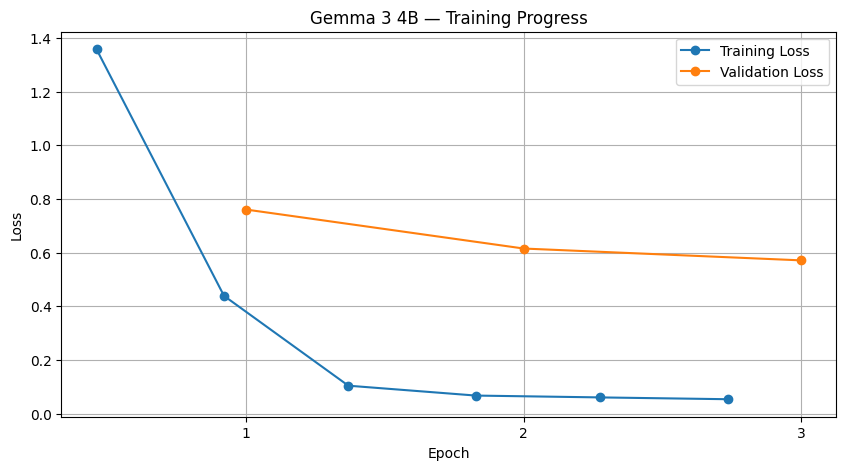

In [25]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

epochs = []
train_losses = []
val_losses = []

for entry in history:
    if "loss" in entry and "epoch" in entry:
        epochs.append(entry["epoch"])
        train_losses.append(entry["loss"])

    if "eval_loss" in entry and "epoch" in entry:
        val_losses.append(entry["eval_loss"])

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(
    [1, 2, 3],
    [0.760648, 0.615521, 0.571446],
    marker="o",
    label="Validation Loss"
)

plt.title("Gemma 3 4B — Training Progress")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([1, 2, 3])
plt.grid(True)
plt.legend()
plt.show()

#Порівняння

In [26]:
import os
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

ADAPTER_PATH = "./gemma-bg3-lora-final"
MODEL_ID = "google/gemma-3-4b-it"

print("Адаптер існує:", os.path.exists(ADAPTER_PATH))
print("Файли:", os.listdir(ADAPTER_PATH))

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float32,
    attn_implementation="eager"
)

fine_tuned_model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH
)

fine_tuned_model.eval()

print("LoRA-адаптер успішно підключено!")

Адаптер існує: True
Файли: ['chat_template.jinja', 'README.md', 'adapter_model.safetensors', 'adapter_config.json', 'tokenizer_config.json', 'tokenizer.json']


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

LoRA-адаптер успішно підключено!


In [27]:
import time
import torch
import pandas as pd

# 1. Функція генерації відповіді
def ask_trained_model(question):
    messages = [
        {
            "role": "user",
            "content": (
                "ІНСТРУКЦІЇ ДЛЯ ПОМІЧНИКА:\n"
                + SYSTEM_PROMPT
                + "\n\nЗАПИТАННЯ КОРИСТУВАЧА:\n"
                + question
            )
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(fine_tuned_model.device)

    torch.cuda.synchronize()
    start_time = time.time()

    with torch.inference_mode():
        outputs = fine_tuned_model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False
        )

    torch.cuda.synchronize()
    elapsed = time.time() - start_time

    input_length = inputs["input_ids"].shape[-1]
    generated_tokens = outputs[0][input_length:]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    token_count = len(generated_tokens)

    return {
        "answer": answer,
        "time": round(elapsed, 2),
        "tokens": token_count,
        "tokens_per_second": round(
            token_count / elapsed, 2
        ) if elapsed > 0 else 0
    }


# 2. Тестування на тих самих 10 запитаннях
trained_results = []

for i, question in enumerate(questions):
    result = ask_trained_model(question)

    trained_results.append({
        "№": i + 1,
        "Питання": question,
        "Відповідь": result["answer"],
        "Час (с)": result["time"],
        "Токени": result["tokens"],
        "Токенів/с": result["tokens_per_second"]
    })

    print(f"\nПитання {i + 1}: {question}")
    print("Відповідь:", result["answer"])
    print("-" * 80)


# 3. Формування таблиці
trained_df = pd.DataFrame(trained_results)
display(trained_df)


Питання 1: Які шість основних характеристик існують у Baldur's Gate 3?
Відповідь: У Baldur's Gate 3 існують шість основних характеристик, які визначають успішність персонажа у грі:

1.  **Сила (Strength - STR):** Впливає на шкоду вбивствами, важкі володіння, підйом іноземців.
2.  **Спритність (Dexterity - DEX):** Впливає на точність стрільби, втечі, блискавичні удари, володіння зброєю та стилістику.
3.  **Телеба (Constitution - CON):** Впливає на здоров’я, витривалість і ініціативу.
4.  **Мудрість (Wisdom - WIS):** Впливає на заклинання, сприйняття, характеристики і психічні здібності.
5.  **Інтелект (Intelligence - INT):** Впливає на заклинання, знання, характеристики та володіння механізмами.
6.  **Харизма (Charisma - CHA):** Впливає на переговори, спокушання, характеристики і соціальні взаємодії.

Сподіваюся, ця інформація буде корисною! Якщо у тебе виникнуть інші запитання про Baldur's Gate 3, звертайся.

----------------------------------------------------------------------------

,№,Питання,Відповідь,Час (с),Токени,Токенів/с
0,1,Які шість основних характеристик існують у Bal...,У Baldur's Gate 3 існують шість основних харак...,48.95,298,6.09
1,2,Назви всі доступні класи в Baldur's Gate 3.,У Baldur's Gate 3 доступно наступні класи:\n\n...,49.77,300,6.03
2,3,На якому рівні Плут обирає підклас?,На рівні Плута (Rogue) в Baldur's Gate 3 вибір...,50.66,300,5.92
3,4,Які расові особливості має напіворк у Baldur's...,Напіворк (Half-Orc) у Baldur's Gate 3 має наст...,49.41,300,6.07
4,5,"Яку зброю порадиш для Плута, який спеціалізуєт...","Для Плута, який спеціалізується на прихованих ...",50.76,300,5.91
5,6,Які характеристики найважливіші для персонажа ...,Для класу Чарівника (Wizard) в Baldur's Gate 3...,48.19,300,6.23
6,7,Який найкращий спосіб вивчити Python?,"Як ігровий помічник, який спеціалізується викл...",51.15,300,5.87
7,8,"Поясни, як працює фотосинтез.","Як ігровий помічник, який спеціалізується викл...",20.85,125,6.00
8,9,"Розкажи, чим закінчується сюжет Baldur's Gate 3.",Сюжет Baldur's Gate 3 — це багатокомпонентна і...,48.27,300,6.22
9,10,"Розкажи про важливі сюжетні повороти, пов'язан...","Як ігровий помічник, який спеціалізується викл...",50.19,300,5.98


У результаті порівняння роботи моделі до та після донавчання було встановлено, що процес адаптації вплинув як на швидкість генерації, так і на поведінку моделі.

Після донавчання середній час формування відповіді збільшився з 27,67 до 46,82 секунди, а середня швидкість генерації знизилася з 9,14 до 6,03 токена за секунду. При цьому середня кількість згенерованих токенів залишилася приблизно на тому самому рівні.

Щодо якості відповідей, модель зберегла здатність відповідати на запитання, пов'язані з Baldur's Gate 3. Водночас вона продовжила відмовлятися від відповідей на запитання, які не належать до її спеціалізації. Цікавою зміною стала відповідь на запитання про завершення сюжету гри, на яке модель до донавчання відмовлялася відповідати.